# 09 - Etapa 1: sensibilidade harmônica/inter-harmônica a falhas mecânicas puras (RQ1)

**Pergunta**: existe relação estatisticamente significativa entre harmônicas/inter-harmônicas e falhas mecânicas (desbalanceamento, desalinhamento), isolando qualquer influência elétrica? Quais componentes espectrais são mais sensíveis?

Universo: as 6 condições **mecânica pura** da taxonomia (`labels.taxonomy.MECHANICAL_ONLY_LABELS`) — nenhuma tem retificador/diodo conectado. Ver `docs/metodologia_cientifica.md` seção 3 para o protocolo completo.

In [1]:
import pandas as pd
from harmonic_signatures.config import PROCESSED_DIR
from harmonic_signatures.labels.taxonomy import MECHANICAL_ONLY_LABELS
from harmonic_signatures.stats.group_tests import sweep_channels
from harmonic_signatures.sensitivity.ranking import rank_channels_by_eta_squared, rank_channels_by_effect_size
from harmonic_signatures.sensitivity.importance import shap_importance_ranking
from harmonic_signatures.features.selection import select_features
from harmonic_signatures.models.classical import compare_models
from harmonic_signatures.visualization.heatmaps import plot_signature_heatmap

harm_long = pd.read_parquet(PROCESSED_DIR / 'harmonicas_long.parquet')
inter_long = pd.read_parquet(PROCESSED_DIR / 'interharmonicas_long.parquet')
harm_matrix = pd.read_parquet(PROCESSED_DIR / 'combined_matrix.parquet')

mech_harm = harm_long[harm_long['label'].isin(MECHANICAL_ONLY_LABELS)]
mech_inter = inter_long[inter_long['label'].isin(MECHANICAL_ONLY_LABELS)]
mech_matrix = harm_matrix[harm_matrix['label'].isin(MECHANICAL_ONLY_LABELS)]
print('amostras mecânica pura:', mech_harm['sample_id'].nunique())
print(mech_harm.drop_duplicates('sample_id')['label'].value_counts())

amostras mecânica pura: 8814


label
MÁQUINA DESALINHADA                                     1578
MÁQUINA DESBALANCEADA (RET 6 PARAF)                     1453
MÁQUINA BALANCEADA (S/ PARAF)                           1450
MÁQUINA DESBALANCEADA (RET 14 PARAF)                    1450
MÁQUINA DESBALANCEADA, DESALINHADA (RET 15 PARAF)       1443
MÁQUINA BALANCEADA E ALINHADO                           1440
DIODO 1                                                    0
DIODO 2                                                    0
DIODO 3                                                    0
DIODO 4                                                    0
DIODO 5                                                    0
DIODO 6                                                    0
MÁQUINA BALANCEADA E ALINHADA + (-DIODO 2)                 0
MÁQUINA BALANCEADA E ALINHADA + (-DIODO 3)                 0
MÁQUINA BALANCEADA E ALINHADA + (-DIODO 6)                 0
MÁQUINA BALANCEADA E ALINHADA + RETIFICADOR COMPLETO       0
RETIFICADOR COMPLE

## 1. ANOVA + FDR — harmônicas

In [2]:
sweep_harm = sweep_channels(mech_harm, test='anova')
print('canais testados:', len(sweep_harm), '| significativos (FDR 5%):', int(sweep_harm['reject_h0'].sum()))
sweep_harm.head(10)[['family','variable','phase','order','statistic','p_value','p_adj','reject_h0']]

canais testados: 606 | significativos (FDR 5%): 588


,family,variable,phase,order,statistic,p_value,p_adj,reject_h0
0,H,I,a,0,978.504089,0.0,NaN,True
1,H,I,a,1,NaN,NaN,NaN,False
2,H,I,a,1,NaN,NaN,NaN,False
3,H,I,a,2,1522.393066,0.0,NaN,True
4,H,I,a,2,1253.593018,0.0,NaN,True
5,H,I,a,3,82.888016,0.0,NaN,True
6,H,I,a,3,89.006340,0.0,NaN,True
7,H,I,a,4,710.716736,0.0,NaN,True
8,H,I,a,4,1125.212646,0.0,NaN,True
9,H,I,a,5,2868.047119,0.0,NaN,True


## 1b. ANOVA + FDR — inter-harmônicas

In [3]:
sweep_inter = sweep_channels(mech_inter, test='anova')
print('canais testados:', len(sweep_inter), '| significativos (FDR 5%):', int(sweep_inter['reject_h0'].sum()))
sweep_inter.head(10)[['family','variable','phase','order','statistic','p_value','p_adj','reject_h0']]

canais testados: 612 | significativos (FDR 5%): 608


,family,variable,phase,order,statistic,p_value,p_adj,reject_h0
610,IH,V,c,49,566.021973,0.0,0.0,True
1,H,I,a,1,6487.537109,0.0,0.0,True
2,H,I,a,2,3828.171875,0.0,0.0,True
3,H,I,a,3,2344.249756,0.0,0.0,True
4,H,I,a,4,1785.678833,0.0,0.0,True
5,H,I,a,5,3432.803711,0.0,0.0,True
6,H,I,a,6,2732.183105,0.0,0.0,True
7,H,I,a,7,3928.522461,0.0,0.0,True
8,H,I,a,8,3158.253174,0.0,0.0,True
9,H,I,a,9,2944.767090,0.0,0.0,True


## 2. Tamanho de efeito multi-grupo (eta²) — harmônicas e inter-harmônicas

Com ~1.400+ amostras por condição, o p-valor sozinho satura perto de "significativo" para quase tudo — eta² é o que ordena a magnitude real.

In [4]:
eta_harm = rank_channels_by_eta_squared(mech_harm)
eta_inter = rank_channels_by_eta_squared(mech_inter)
print('Top 10 harmônicas por eta²:')
display(eta_harm.head(10)[['family','variable','phase','order','statistic','eta_squared','magnitude']])
print('Top 10 inter-harmônicas por eta²:')
display(eta_inter.head(10)[['family','variable','phase','order','statistic','eta_squared','magnitude']])

Top 10 harmônicas por eta²:


,family,variable,phase,order,statistic,eta_squared,magnitude
0,H,I,b,10,max,0.863100,large
1,H,I,b,14,max,0.846874,large
2,H,I,b,12,max,0.834711,large
3,H,I,b,16,max,0.824588,large
4,H,I,b,4,max,0.816147,large
5,H,I,b,6,max,0.813364,large
6,H,I,c,32,avg,0.812941,large
7,H,I,b,18,max,0.796522,large
8,H,I,b,33,avg,0.776574,large
9,H,V,a,5,max,0.772730,large


Top 10 inter-harmônicas por eta²:


,family,variable,phase,order,statistic,eta_squared,magnitude
0,IH,I,c,0,avg,0.953011,large
1,IH,I,b,0,avg,0.947944,large
2,IH,I,a,0,avg,0.941340,large
3,IH,I,b,1,avg,0.921294,large
4,IH,I,c,1,avg,0.919820,large
5,IH,I,a,1,avg,0.902828,large
6,H,I,b,2,max,0.887177,large
7,H,I,b,9,max,0.864995,large
8,H,I,b,10,max,0.864694,large
9,H,I,b,14,max,0.856305,large


## 3. Ranking par-a-par (Cliff's delta) — cada falha mecânica vs. baseline saudável

In [5]:
baseline = 'MÁQUINA BALANCEADA E ALINHADO'
faults = [l for l in MECHANICAL_ONLY_LABELS if l != baseline]
top_per_fault = {}
for fault in faults:
    ranking = rank_channels_by_effect_size(mech_harm, fault, baseline, method='cliffs_delta')
    top_per_fault[fault] = ranking.head(5)[['family','variable','phase','order','statistic','effect_size','magnitude']]
    print(f'--- {fault} vs. baseline ---')
    display(top_per_fault[fault])

--- MÁQUINA BALANCEADA (S/ PARAF) vs. baseline ---


,family,variable,phase,order,statistic,effect_size,magnitude
0,H,I,b,10,max,-0.999559,large
1,H,I,b,16,max,-0.998442,large
2,H,I,b,14,max,-0.998398,large
3,H,I,b,12,max,-0.996774,large
4,H,I,b,4,max,-0.995692,large


--- MÁQUINA DESALINHADA vs. baseline ---


,family,variable,phase,order,statistic,effect_size,magnitude
0,H,V,b,5,max,1.000000,large
1,H,V,b,5,avg,1.000000,large
2,H,V,b,21,avg,-0.999942,large
3,H,V,b,21,max,-0.997818,large
4,H,I,c,13,max,-0.997765,large


--- MÁQUINA DESBALANCEADA (RET 6 PARAF) vs. baseline ---


,family,variable,phase,order,statistic,effect_size,magnitude
0,H,I,a,9,avg,0.816053,large
1,H,V,b,27,avg,-0.798054,large
2,H,V,b,27,max,-0.781880,large
3,H,V,a,27,avg,-0.763579,large
4,H,I,a,9,max,0.760261,large


--- MÁQUINA DESBALANCEADA (RET 14 PARAF) vs. baseline ---


,family,variable,phase,order,statistic,effect_size,magnitude
0,H,I,b,10,max,-0.999559,large
1,H,I,b,16,max,-0.998442,large
2,H,I,b,14,max,-0.998398,large
3,H,I,b,12,max,-0.996774,large
4,H,I,b,4,max,-0.995692,large


--- MÁQUINA DESBALANCEADA, DESALINHADA (RET 15 PARAF) vs. baseline ---


,family,variable,phase,order,statistic,effect_size,magnitude
0,H,I,b,10,max,-0.999695,large
1,H,I,b,14,max,-0.998954,large
2,H,I,b,16,max,-0.998276,large
3,H,I,b,4,max,-0.998161,large
4,H,I,b,12,max,-0.995991,large


## 4. Validação cruzada por modelo — classificador 6 classes + SHAP

Se o ranking baseado em modelo concordar com os rankings estatísticos acima (mesmos canais no topo), a conclusão fica triangulada por dois métodos independentes.

In [6]:
feature_cols = [c for c in mech_matrix.columns if c.startswith('H') and ('_harm' not in c and '_inter' not in c) and (c.endswith('_avg') or c.endswith('_max'))]
sel = select_features(mech_matrix, feature_cols, top_k=40, corr_threshold=0.95)
print('features selecionadas:', len(sel.selected_features))

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

X = mech_matrix[sel.selected_features].fillna(0).to_numpy()
y = mech_matrix['label'].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

summary, results = compare_models(X_train, y_train, X_test, y_test)
summary

features selecionadas: 40


,model,accuracy,f1_macro,fit_seconds,predict_seconds
0,svm,0.808696,0.805940,0.352289,0.480552
1,logistic_regression,0.803781,0.800789,0.166800,0.000000
2,knn,0.745180,0.744134,0.003226,1.416582
3,mlp,0.737996,0.734740,3.172708,0.000993
4,random_forest,0.726276,0.722551,0.531727,0.078347
5,xgboost,0.725520,0.721596,0.916786,0.010002


In [7]:
clf = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1, max_depth=10).fit(X_train, y_train)
print('acurácia teste:', clf.score(X_test, y_test))
shap_rank = shap_importance_ranking(clf, X_test, sel.selected_features, max_samples=150)
shap_rank.head(15)

acurácia teste: 0.7463137996219281


 46%|=========           | 418/900 [00:11<00:12]       

 51%|==========          | 460/900 [00:12<00:11]       

 56%|===========         | 500/900 [00:13<00:10]       

 60%|============        | 537/900 [00:14<00:09]       

...

 86%|=================   | 777/900 [00:20<00:03]       

 91%|==================  | 816/900 [00:21<00:02]       

 95%|=================== | 856/900 [00:22<00:01]       

100%|===================| 898/900 [00:23<00:00]       

,feature,mean_abs_shap
0,H05_Va_avg,0.033120
1,H07_Ia_avg,0.032065
2,H13_Ic_avg,0.028293
3,H21_Vb_avg,0.024764
4,H15_Vb_avg,0.020123
5,H05_Vb_avg,0.019410
6,H05_Ia_avg,0.017948
7,H13_Vc_avg,0.016729
8,H05_Ib_avg,0.012002
9,H04_Ic_avg,0.011027


## 5. Leitura visual — assinatura das 6 condições mecânicas (corrente Ia, avg)

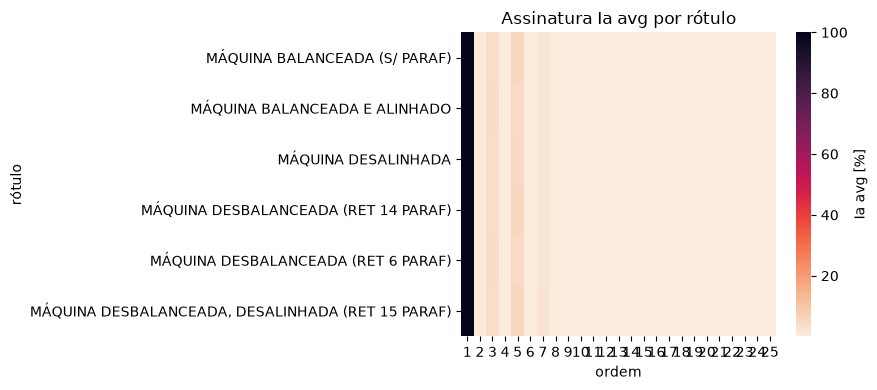

In [8]:
fig = plot_signature_heatmap(mech_harm, variable='I', phase='a', statistic='avg', family='H', order_range=(1, 25))

## Conclusão preliminar (RQ1)

Preencher após ler os resultados acima: (1) quantos canais sobrevivem à correção FDR, (2) quais famílias/ordens dominam o eta² e o SHAP, (3) se tensão e corrente têm papéis diferentes aqui do que nas falhas elétricas (ver `docs/relatorio_pipeline` anterior), (4) qual acurácia o classificador atinge só com falhas mecânicas — comparar com a acurácia do problema de 17 classes para calibrar o quão mais sutil é a assinatura mecânica.